# 01 — EDA & Audit Data PM2.5 Bandung

**Tujuan:** mengaudit data mentah sebelum pembersihan dan pemodelan. Notebook ini tidak menghapus atau mengubah baris pada `raw.csv`.

**Pemeriksaan yang dilakukan**
1. Struktur, tipe data, dan nama kolom
2. Rentang waktu dan format timestamp
3. Ejaan/nama stasiun
4. Missing values
5. Nilai sentinel `-999`
6. Duplikat penuh
7. Konflik kunci (stasiun + waktu)
8. Gap data per jam untuk setiap stasiun
9. Statistik deskriptif dan visualisasi

**Output:** tabel CSV di `outputs/tables/` dan plot PNG di `outputs/plots/`.

> Letakkan `raw.csv` di folder yang sama dengan notebook. Jika dijalankan di Google Colab, unggah `raw.csv` ketika diminta. Periksa bagian **Konfigurasi kolom** jika deteksi otomatis tidak tepat.


In [35]:
# 0. Persiapan
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

OUTPUT_DIR = Path("outputs")
TABLE_DIR = OUTPUT_DIR / "tables"
PLOT_DIR = OUTPUT_DIR / "plots"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

print("Folder output siap:", OUTPUT_DIR.resolve())


Folder output siap: /content/outputs


In [36]:
# 1. Membaca data mentah
DATA_PATH = Path("raw.csv")

if not DATA_PATH.exists():
    try:
        from google.colab import files
        print("raw.csv belum ditemukan. Silakan unggah file raw.csv.")
        uploaded = files.upload()
        candidates = [name for name in uploaded if name.lower().endswith(".csv")]
        if not candidates:
            raise FileNotFoundError("Tidak ada file CSV yang diunggah.")
        DATA_PATH = Path(candidates[0])
    except ImportError:
        raise FileNotFoundError(
            "Letakkan raw.csv di folder yang sama dengan notebook, lalu jalankan ulang sel ini."
        )

# Coba beberapa encoding umum. Deteksi separator dilakukan oleh Python engine.
last_error = None
for enc in ["utf-8", "utf-8-sig", "latin1"]:
    try:
        df_raw = pd.read_csv(DATA_PATH, encoding=enc, sep=None, engine="python")
        print(f"Berhasil membaca {DATA_PATH} dengan encoding={enc}")
        break
    except Exception as exc:
        last_error = exc
else:
    raise last_error

print("Ukuran data:", df_raw.shape)
display(df_raw.head())


Berhasil membaca raw.csv dengan encoding=utf-8
Ukuran data: (87650, 8)


,waktu,stasiun,pm25_ugm3,suhu_C,kelembaban_pct,kecepatan_angin_ms,arah_angin_deg,curah_hujan_mm
0,2024-07-01 00:00,Dago,26.9,19.1,89.0,0.9,112.0,0.0
1,2024-07-01 01:00,Dago,25.3,18.4,86.0,1.2,158.0,0.0
2,2024-07-01 02:00,Dago,27.8,17.3,95.0,0.8,97.0,0.0
3,2024-07-01 03:00,Dago,26.0,16.6,89.0,0.8,66.0,0.0
4,2024-07-01 04:00,Dago,26.6,16.0,91.0,0.1,104.0,0.0


## 2. Konfigurasi kolom

Notebook mencoba mengenali kolom stasiun, waktu, dan PM2.5 berdasarkan nama yang umum. **Periksa hasil deteksi di bawah.** Jika salah, isi variabel override secara manual, misalnya `STATION_COL = "station_name"`.

Jika dataset memiliki kolom tanggal dan jam terpisah, gabungkan terlebih dahulu menjadi satu kolom timestamp di bagian konfigurasi.

In [37]:
# Isi dengan nama kolom yang tepat jika deteksi otomatis tidak sesuai.
STATION_COL = "stasiun"       # diatur manual
TIME_COL = "waktu"            # diatur manual ke "waktu" untuk mengatasi error
PM25_COL = "pm25_ugm3"        # diatur manual

def norm_col(s):
    return re.sub(r"[^a-z0-9]+", "", str(s).lower())

def find_col(columns, candidates):
    lookup = {norm_col(c): c for c in columns}
    for cand in candidates:
        if norm_col(cand) in lookup:
            return lookup[norm_col(cand)]
    # pencocokan parsial untuk variasi penamaan
    for c in columns:
        nc = norm_col(c)
        if any(norm_col(x) in nc for x in candidates):
            return c
    return None

if STATION_COL is None:
    STATION_COL = find_col(df_raw.columns, ["station", "stasiun", "station_name", "lokasi"])
if TIME_COL is None:
    TIME_COL = find_col(df_raw.columns, ["timestamp", "datetime", "date_time", "tanggalwaktu", "time", "date", "waktu"])
if PM25_COL is None:
    PM25_COL = find_col(df_raw.columns, ["pm25", "pm2.5", "pm_2_5", "pm 2.5"])

print("Kolom terdeteksi:")
print("  Stasiun :", STATION_COL)
print("  Waktu   :", TIME_COL)
print("  PM2.5   :", PM25_COL)
print("\nSemua kolom:", df_raw.columns.tolist())

if STATION_COL is None or TIME_COL is None:
    raise ValueError(
        "Kolom stasiun/waktu belum terdeteksi. Isi STATION_COL dan TIME_COL secara manual, lalu jalankan ulang."
    )
if PM25_COL is None:
    print("PERINGATAN: kolom PM2.5 belum terdeteksi. Pemeriksaan khusus PM2.5 akan dilewati.")

Kolom terdeteksi:
  Stasiun : stasiun
  Waktu   : waktu
  PM2.5   : pm25_ugm3

Semua kolom: ['waktu', 'stasiun', 'pm25_ugm3', 'suhu_C', 'kelembaban_pct', 'kecepatan_angin_ms', 'arah_angin_deg', 'curah_hujan_mm']


## 3. Struktur data dan tipe data

In [38]:
# Simpan ringkasan struktur
structure = pd.DataFrame({
    "kolom": df_raw.columns,
    "tipe_data": [str(t) for t in df_raw.dtypes],
    "jumlah_non_null": [int(df_raw[c].notna().sum()) for c in df_raw.columns],
    "jumlah_missing": [int(df_raw[c].isna().sum()) for c in df_raw.columns],
    "persen_missing": [(df_raw[c].isna().mean() * 100).round(2) for c in df_raw.columns]
})
display(structure)
structure.to_csv(TABLE_DIR / "01_struktur_tipe_data.csv", index=False)

print("Jumlah baris:", len(df_raw))
print("Jumlah kolom:", df_raw.shape[1])
print("\nInfo tipe data:")
df_raw.info()


,kolom,tipe_data,jumlah_non_null,jumlah_missing,persen_missing
0,waktu,object,87650,0,0.00
1,stasiun,object,87650,0,0.00
2,pm25_ugm3,float64,87506,144,0.16
3,suhu_C,float64,87506,144,0.16
4,kelembaban_pct,float64,87506,144,0.16
5,kecepatan_angin_ms,float64,86773,877,1.00
6,arah_angin_deg,float64,87650,0,0.00
7,curah_hujan_mm,float64,87650,0,0.00


Jumlah baris: 87650
Jumlah kolom: 8

Info tipe data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87650 entries, 0 to 87649
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   waktu               87650 non-null  object 
 1   stasiun             87650 non-null  object 
 2   pm25_ugm3           87506 non-null  float64
 3   suhu_C              87506 non-null  float64
 4   kelembaban_pct      87506 non-null  float64
 5   kecepatan_angin_ms  86773 non-null  float64
 6   arah_angin_deg      87650 non-null  float64
 7   curah_hujan_mm      87650 non-null  float64
dtypes: float64(6), object(2)
memory usage: 5.3+ MB


## 4. Parsing timestamp dan rentang waktu

In [39]:
df = df_raw.copy()
df["_timestamp_parsed"] = pd.to_datetime(df[TIME_COL], errors="coerce")

time_summary = pd.DataFrame([{
    "jumlah_baris": len(df),
    "timestamp_valid": int(df["_timestamp_parsed"].notna().sum()),
    "timestamp_gagal_parse": int(df["_timestamp_parsed"].isna().sum()),
    "waktu_mulai": df["_timestamp_parsed"].min(),
    "waktu_akhir": df["_timestamp_parsed"].max(),
    "jumlah_timestamp_unik": int(df["_timestamp_parsed"].nunique())
}])
display(time_summary)
time_summary.to_csv(TABLE_DIR / "02_rentang_waktu.csv", index=False)

bad_time = df[df["_timestamp_parsed"].isna()]
bad_time.to_csv(TABLE_DIR / "baris_timestamp_gagal_parse.csv", index=False)


,jumlah_baris,timestamp_valid,timestamp_gagal_parse,waktu_mulai,waktu_akhir,jumlah_timestamp_unik
0,87650,87650,0,2024-07-01,2026-06-30 23:00:00,17520


## 5. Audit ejaan dan variasi nama stasiun

In [40]:

# Normalisasi variasi nama stasiun
# Kolom asli tetap dipertahankan

df["_station_std"] = (
    df[STATION_COL]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
)

station_mapping = {
    "dago": "Dago",
    "antapani": "Antapani",
    "cibeureum": "Cibeureum",
    "ujungberung": "Ujungberung",
    "ujung berung": "Ujungberung",
    "soekarno-hatta": "Soekarno-Hatta",
    "soekarno hatta": "Soekarno-Hatta",
    "soetta": "Soekarno-Hatta"
}

df["_station_std"] = df["_station_std"].map(station_mapping)

print("Distribusi nama stasiun setelah normalisasi:")
display(df["_station_std"].value_counts(dropna=False))

print("\nNama stasiun yang belum terpetakan:")
display(
    df.loc[df["_station_std"].isna(), STATION_COL]
    .value_counts(dropna=False)
)

# Simpan hasil normalisasi
df[[STATION_COL, "_station_std"]].drop_duplicates().to_csv(
    TABLE_DIR / "03b_pemetaan_nama_stasiun.csv",
    index=False
)



Distribusi nama stasiun setelah normalisasi:


,count
_station_std,
Ujungberung,17545
Antapani,17530
Dago,17527
Cibeureum,17526
Soekarno-Hatta,17522



Nama stasiun yang belum terpetakan:


,count
stasiun,


## 6. Missing values

,kolom,jumlah_missing,persentase_missing
5,kecepatan_angin_ms,877,1.00
4,kelembaban_pct,144,0.16
2,pm25_ugm3,144,0.16
3,suhu_C,144,0.16
6,arah_angin_deg,0,0.00
7,curah_hujan_mm,0,0.00
1,stasiun,0,0.00
0,waktu,0,0.00


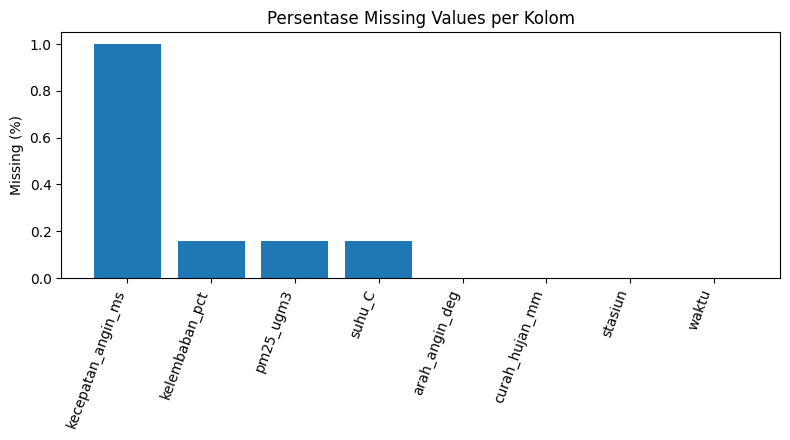

In [41]:
missing = pd.DataFrame({
    "kolom": df_raw.columns,
    "jumlah_missing": [int(df_raw[c].isna().sum()) for c in df_raw.columns],
    "persentase_missing": [(df_raw[c].isna().mean() * 100).round(2) for c in df_raw.columns]
}).sort_values(["jumlah_missing", "kolom"], ascending=[False, True])
display(missing)
missing.to_csv(TABLE_DIR / "04_missing_values.csv", index=False)

plt.figure(figsize=(max(8, len(missing) * 0.65), 4.5))
plt.bar(missing["kolom"].astype(str), missing["persentase_missing"])
plt.ylabel("Missing (%)")
plt.title("Persentase Missing Values per Kolom")
plt.xticks(rotation=70, ha="right")
plt.tight_layout()
plt.savefig(PLOT_DIR / "01_missing_values.png", dpi=160)
plt.show()


## 7. Nilai sentinel -999

In [42]:
sentinel_summary = []
sentinel_rows = pd.DataFrame()
if PM25_COL is not None:
    pm_numeric = pd.to_numeric(df[PM25_COL], errors="coerce")
    mask_999 = pm_numeric.eq(-999)
    sentinel_summary.append({
        "kolom": PM25_COL,
        "jumlah_-999": int(mask_999.sum()),
        "persentase_dari_seluruh_baris": round(mask_999.mean() * 100, 3)
    })
    sentinel_rows = df.loc[mask_999].copy()
    display(pd.DataFrame(sentinel_summary))
    sentinel_rows.to_csv(TABLE_DIR / "baris_pm25_minus999.csv", index=False)
else:
    print("Dilewati: kolom PM2.5 belum dikonfigurasi.")
pd.DataFrame(sentinel_summary).to_csv(TABLE_DIR / "05_sentinel_minus999.csv", index=False)


,kolom,jumlah_-999,persentase_dari_seluruh_baris
0,pm25_ugm3,173,0.197


## 8. Duplikat penuh

In [43]:
# Duplikat penuh dihitung pada seluruh kolom asli, tidak termasuk kolom bantu.
full_dup_mask = df_raw.duplicated(keep=False)
full_dup_summary = pd.DataFrame([{
    "jumlah_baris_duplikat_dengan_pasangan": int(full_dup_mask.sum()),
    "jumlah_baris_duplikat_setelah_baris_pertama": int(df_raw.duplicated().sum()),
    "jumlah_grup_baris_identik": int(df_raw.loc[full_dup_mask].drop_duplicates().shape[0])
}])
display(full_dup_summary)
full_dup_summary.to_csv(TABLE_DIR / "06_ringkasan_duplikat_penuh.csv", index=False)
df_raw.loc[full_dup_mask].to_csv(TABLE_DIR / "baris_duplikat_penuh.csv", index=False)


,jumlah_baris_duplikat_dengan_pasangan,jumlah_baris_duplikat_setelah_baris_pertama,jumlah_grup_baris_identik
0,796,398,398


## 9. Konflik kunci stasiun + timestamp

In [44]:

# Audit konflik kunci setelah normalisasi nama stasiun

# Buat salinan analisis tanpa duplikat penuh
df_analysis = df.drop_duplicates().copy()

# Pastikan timestamp sudah berbentuk datetime
df_analysis["_timestamp"] = pd.to_datetime(
    df_analysis[TIME_COL],
    errors="coerce"
)

# Periksa kombinasi stasiun dan timestamp
key_valid = df_analysis.dropna(
    subset=["_station_std", "_timestamp"]
).copy()

key_check = (
    key_valid.groupby(
        ["_station_std", "_timestamp"]
    )
    .agg(
        jumlah_baris=(PM25_COL, "size"),
        jumlah_nilai_pm25=(PM25_COL, "nunique"),
        nilai_min=(PM25_COL, "min"),
        nilai_maks=(PM25_COL, "max")
    )
    .reset_index()
)

# Kunci yang muncul lebih dari sekali
duplicate_keys = key_check[
    key_check["jumlah_baris"] > 1
].copy()

duplicate_keys["konflik_nilai_pm25"] = (
    duplicate_keys["jumlah_nilai_pm25"] > 1
)

display(duplicate_keys.head(30))

print("Jumlah kunci berulang:", len(duplicate_keys))
print(
    "Jumlah konflik nilai PM2.5:",
    duplicate_keys["konflik_nilai_pm25"].sum()
)

duplicate_keys.to_csv(
    TABLE_DIR / "07_konflik_kunci_stasiun_waktu_revisi.csv",
    index=False
)

# Simpan detail baris yang memiliki kunci berulang
conflict_detail = key_valid.merge(
    duplicate_keys[["_station_std", "_timestamp"]],
    on=["_station_std", "_timestamp"],
    how="inner"
)

conflict_detail.to_csv(
    TABLE_DIR / "detail_baris_konflik_kunci_revisi.csv",
    index=False
)


,_station_std,_timestamp,jumlah_baris,jumlah_nilai_pm25,nilai_min,nilai_maks,konflik_nilai_pm25
61071,Soekarno-Hatta,2025-06-30 17:00:00,2,2,42.5,44.5,True
61072,Soekarno-Hatta,2025-06-30 18:00:00,2,2,40.2,44.6,True
61073,Soekarno-Hatta,2025-06-30 19:00:00,2,2,39.6,54.1,True
61074,Soekarno-Hatta,2025-06-30 20:00:00,2,2,44.1,49.5,True
61075,Soekarno-Hatta,2025-06-30 21:00:00,2,2,38.6,39.8,True
61076,Soekarno-Hatta,2025-06-30 22:00:00,2,2,41.1,49.5,True
61077,Soekarno-Hatta,2025-06-30 23:00:00,2,2,30.8,49.3,True


Jumlah kunci berulang: 7
Jumlah konflik nilai PM2.5: 7


## 10. Gap data per jam per stasiun

,stasiun,jam_teramati,jam_diharapkan,jumlah_jam_gap,persentase_gap
0,Antapani,17456,17520,64,0.37
1,Cibeureum,17443,17520,77,0.44
2,Dago,17455,17520,65,0.37
3,Soekarno-Hatta,17437,17520,83,0.47
4,Ujungberung,17454,17520,66,0.38


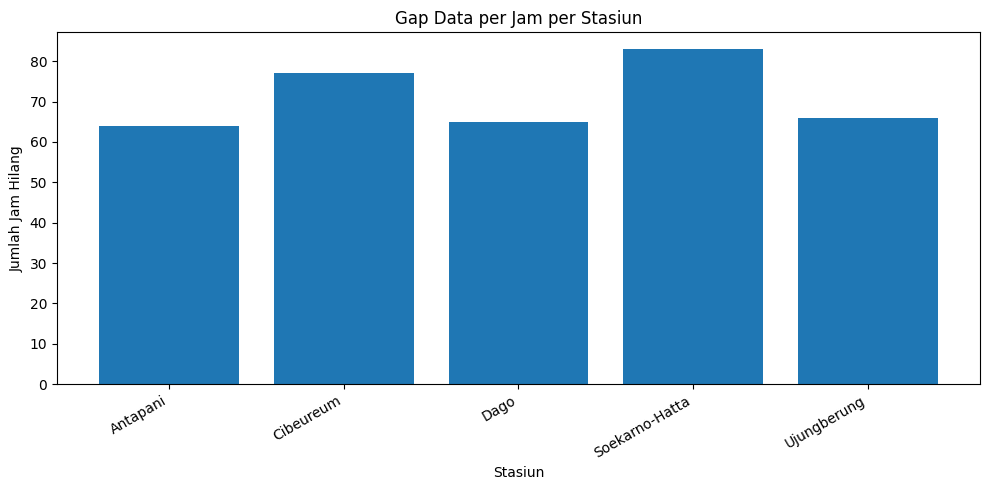

In [45]:

# Audit gap data per jam berdasarkan stasiun standar

valid_ts = df_analysis.dropna(
    subset=["_station_std", "_timestamp"]
).copy()

valid_ts["_hour"] = valid_ts["_timestamp"].dt.floor("h")

gap_rows = []
gap_detail_rows = []

for station, group in valid_ts.groupby("_station_std"):

    observed = pd.DatetimeIndex(
        group["_hour"].unique()
    ).sort_values()

    if len(observed) == 0:
        continue

    full_hours = pd.date_range(
        observed.min(),
        observed.max(),
        freq="h"
    )

    missing_hours = full_hours.difference(observed)

    gap_rows.append({
        "stasiun": station,
        "jam_teramati": len(observed),
        "jam_diharapkan": len(full_hours),
        "jumlah_jam_gap": len(missing_hours),
        "persentase_gap": round(
            len(missing_hours) / len(full_hours) * 100,
            2
        )
    })

    for missing_time in missing_hours:
        gap_detail_rows.append({
            "stasiun": station,
            "jam_hilang": missing_time
        })

gap_summary = pd.DataFrame(gap_rows)

display(gap_summary)

gap_summary.to_csv(
    TABLE_DIR / "08_gap_per_jam_per_stasiun_revisi.csv",
    index=False
)

pd.DataFrame(gap_detail_rows).to_csv(
    TABLE_DIR / "detail_timestamp_gap_per_jam_revisi.csv",
    index=False
)

# Plot gap per jam
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    gap_summary["stasiun"],
    gap_summary["jumlah_jam_gap"]
)

ax.set_title("Gap Data per Jam per Stasiun")
ax.set_xlabel("Stasiun")
ax.set_ylabel("Jumlah Jam Hilang")

plt.xticks(rotation=30, ha="right")
fig.tight_layout()

fig.savefig(
    PLOT_DIR / "02_gap_per_jam_stasiun_revisi.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()


## 11. Statistik deskriptif

In [46]:
# Statistik numerik seluruh kolom yang berhasil dibaca sebagai numerik
numeric_stats = df_raw.describe(include=[np.number]).T.reset_index().rename(columns={"index": "kolom"})
display(numeric_stats)
numeric_stats.to_csv(TABLE_DIR / "09_statistik_deskriptif_numerik.csv", index=False)

# Statistik khusus PM2.5; -999 tetap ditampilkan dalam statistik mentah, lalu statistik valid disediakan terpisah.
if PM25_COL is not None:
    pm_all = pd.to_numeric(df[PM25_COL], errors="coerce")
    pm_valid = pm_all[(pm_all.notna()) & (pm_all != -999)]
    pm_stats = pd.DataFrame({
        "metrik": ["jumlah_nilai_terbaca", "jumlah_minus_999", "jumlah_valid_non_minus_999",
                   "mean_valid", "median_valid", "std_valid", "min_valid", "q1_valid",
                   "q3_valid", "max_valid"],
        "nilai": [int(pm_all.notna().sum()), int(pm_all.eq(-999).sum()), int(pm_valid.notna().sum()),
                  pm_valid.mean(), pm_valid.median(), pm_valid.std(), pm_valid.min(),
                  pm_valid.quantile(.25), pm_valid.quantile(.75), pm_valid.max()]
    })
    display(pm_stats)
    pm_stats.to_csv(TABLE_DIR / "10_statistik_pm25_valid.csv", index=False)


,kolom,count,mean,std,min,25%,50%,75%,max
0,pm25_ugm3,87506.0,23.992318,47.184571,-999.0,17.2,24.0,32.6,128.4
1,suhu_C,87506.0,23.056426,3.669410,12.0,19.8,23.1,26.3,31.9
2,kelembaban_pct,87506.0,80.837405,9.854038,51.0,73.0,81.0,89.0,100.0
3,kecepatan_angin_ms,86773.0,1.949231,1.101400,0.1,1.0,2.0,2.7,7.9
4,arah_angin_deg,87650.0,179.366207,84.512295,0.0,110.0,178.0,248.0,360.0
5,curah_hujan_mm,87650.0,0.377724,1.522590,0.0,0.0,0.0,0.0,24.9


,metrik,nilai
0,jumlah_nilai_terbaca,87506.000000
1,jumlah_minus_999,173.000000
2,jumlah_valid_non_minus_999,87333.000000
3,mean_valid,26.018788
4,median_valid,24.100000
5,std_valid,12.393582
6,min_valid,0.000000
7,q1_valid,17.300000
8,q3_valid,32.600000
9,max_valid,128.400000


## 12. Plot distribusi dan deret waktu PM2.5

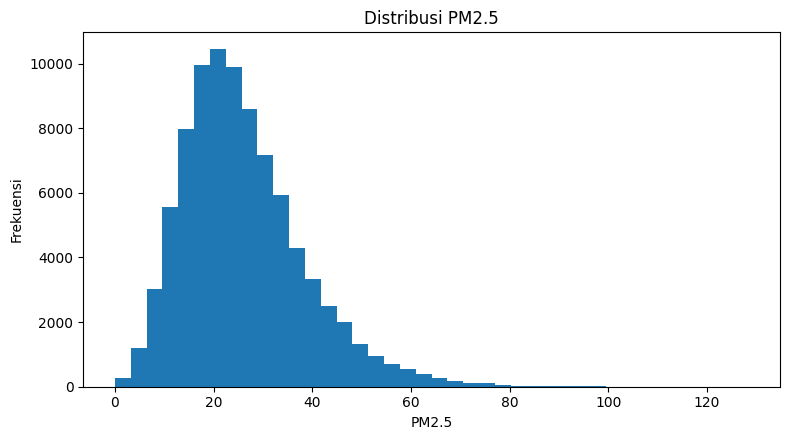

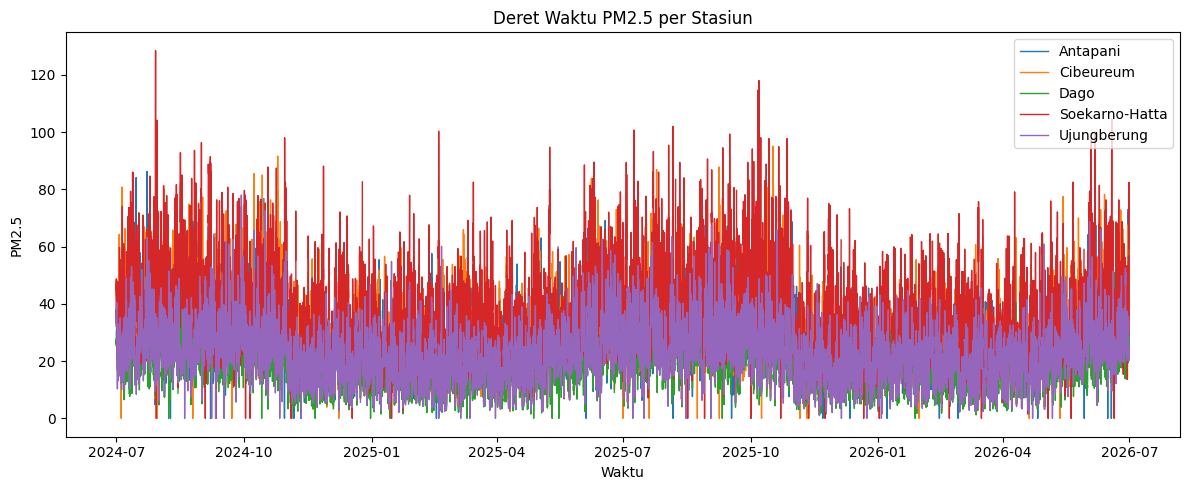

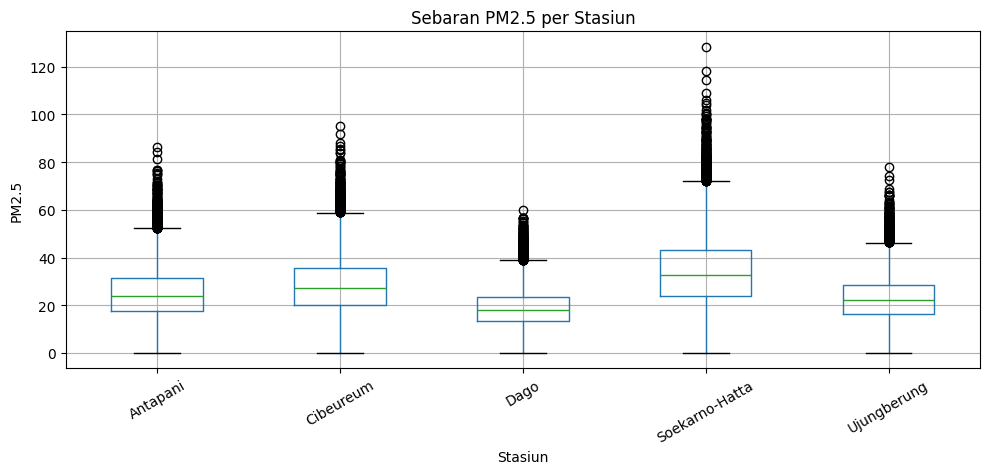

Semua plot berhasil dibuat.


In [47]:
if PM25_COL is not None:
 plot_df = df_analysis.copy()

plot_df["_pm25_num"] = pd.to_numeric(
    plot_df[PM25_COL],
    errors="coerce"
)

plot_df = plot_df[
    plot_df["_pm25_num"].notna()
    & plot_df["_pm25_num"].ne(-999)
    & plot_df["_timestamp"].notna()
    & plot_df["_station_std"].notna()
].copy()

# 1. Histogram
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.hist(plot_df["_pm25_num"], bins=40)
ax.set_title("Distribusi PM2.5")
ax.set_xlabel("PM2.5")
ax.set_ylabel("Frekuensi")

fig.tight_layout()
fig.savefig(PLOT_DIR / "03_distribusi_pm25_revisi.png", dpi=160)
plt.show()

# 2. Deret waktu per stasiun
fig, ax = plt.subplots(figsize=(12, 5))

for station, group in plot_df.groupby("_station_std"):
    hourly = (
        group.set_index("_timestamp")["_pm25_num"]
        .sort_index()
        .resample("h")
        .mean()
    )
    ax.plot(hourly.index, hourly.values, label=station, linewidth=1)

ax.set_title("Deret Waktu PM2.5 per Stasiun")
ax.set_xlabel("Waktu")
ax.set_ylabel("PM2.5")
ax.legend()

fig.tight_layout()
fig.savefig(PLOT_DIR / "04_deret_waktu_pm25_revisi.png", dpi=160)
plt.show()

# 3. Boxplot per stasiun
fig, ax = plt.subplots(figsize=(10, 5))

plot_df.boxplot(
    column="_pm25_num",
    by="_station_std",
    ax=ax,
    rot=30
)

ax.set_title("Sebaran PM2.5 per Stasiun")
ax.set_xlabel("Stasiun")
ax.set_ylabel("PM2.5")

fig.suptitle("")
fig.tight_layout()

fig.savefig(
    PLOT_DIR / "05_boxplot_pm25_revisi.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

print("Semua plot berhasil dibuat.")


## 13. Ringkasan temuan otomatis

Tabel ini merangkum indikator audit utama. Interpretasi akhir tetap perlu dilakukan oleh anggota tim; notebook tidak memutuskan baris mana yang harus dihapus atau diperbaiki.

In [48]:
summary_items = [
    ("Jumlah baris mentah", len(df_raw)),
    ("Jumlah kolom", df_raw.shape[1]),
    ("Timestamp gagal parse", int(df["_timestamp_parsed"].isna().sum())),
    ("Label stasiun unik setelah normalisasi", int(df["_station_std"].nunique(dropna=True))),
    ("Baris duplikat penuh (di luar kemunculan pertama)", int(df_raw.duplicated().sum())),
    ("Kunci stasiun-waktu berulang", int(len(duplicate_keys))),
    ("Total jam gap antarstasiun", int(gap_summary["jumlah_jam_gap"].sum()) if not gap_summary.empty else 0),
]
if PM25_COL is not None:
    summary_items.append(("Nilai PM2.5 -999", int(pd.to_numeric(df[PM25_COL], errors="coerce").eq(-999).sum())))
audit_summary = pd.DataFrame(summary_items, columns=["indikator", "nilai"])
display(audit_summary)
audit_summary.to_csv(TABLE_DIR / "00_ringkasan_temuan_audit.csv", index=False)

print("\nAudit selesai.")
print("Tabel tersimpan di:", TABLE_DIR.resolve())
print("Plot tersimpan di:", PLOT_DIR.resolve())


,indikator,nilai
0,Jumlah baris mentah,87650
1,Jumlah kolom,8
2,Timestamp gagal parse,0
3,Label stasiun unik setelah normalisasi,5
4,Baris duplikat penuh (di luar kemunculan pertama),398
5,Kunci stasiun-waktu berulang,7
6,Total jam gap antarstasiun,355
7,Nilai PM2.5 -999,173



Audit selesai.
Tabel tersimpan di: /content/outputs/tables
Plot tersimpan di: /content/outputs/plots


## 14. Checklist bukti selesai

Sebelum menyerahkan hasil audit, pastikan:
- [ ] Notebook dijalankan dari sel pertama sampai terakhir tanpa error.
- [ ] Nama kolom stasiun, waktu, dan PM2.5 sudah diverifikasi.
- [ ] Rentang waktu dan timestamp gagal parse sudah diperiksa.
- [ ] Variasi ejaan stasiun sudah ditinjau (belum otomatis disatukan).
- [ ] Missing, `-999`, duplikat penuh, dan konflik kunci sudah ditinjau.
- [ ] Gap per jam tiap stasiun sudah ditinjau.
- [ ] Statistik dan seluruh plot sudah muncul.
- [ ] Folder `outputs/tables/` dan `outputs/plots/` disertakan saat mengumpulkan.

**Catatan pelaporan:** bedakan *duplikat penuh* (seluruh kolom identik) dari *konflik kunci* (stasiun dan waktu sama, tetapi baris/nilai dapat berbeda). Jangan menghapus data pada tahap audit. Catat keputusan pembersihan pada notebook/tahap berikutnya.